<a href="https://colab.research.google.com/github/KatiaItzelCortes/Simulaci-n-2/blob/main/MCMC_Algoritmo_de_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## MCMC. Algoritmo de Metropolis
Si se elije q como una $N(0,σ)$ se tiene el sampler más simple, con:


$ \alpha (x,y) = min \{ \frac{f(y)}{f(x)}, 1 \} $ y $y=x+z$   

  $Z \sim (N(0, σ), N(0, σ))$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random as r

1. Inicializar $X_1 = (X_1, X_2)$. Hacer $t = 1$.

2. Generar $Z_1,  \sim  N(0,1)$ independientemente

3. Generar $U \sim U[0,1]$

In [ ]:
def funcion(x1, x2):
    exponente = -( (x1**2)*(x2**2) + x1**2 + x2**2 - 8*x1 - 8*x2 ) / 2
    return (1 / 20216.335877) * np.exp(exponente)

def caminata(x1, x2, N):
    xt = (x1, x2)
    muestras_x1 = []
    muestras_x2 = []

    for t in range(N):
        z1 = np.random.normal(0,1)
        z2 = np.random.normal(0,1)
        Z = (z1, z2)

        Y = (xt[0] + Z[0], xt[1] + Z[1])

        f_xt = funcion(xt[0], xt[1])
        f_Y = funcion(Y[0], Y[1])

        if f_xt == 0:
            alp = 1.0 if f_Y > 0 else 0.0
        else:
            alp = min(1.0, f_Y / f_xt)

        u = r.uniform(0, 1)

        if u < alp:
            xt = Y  # x_t+1 = Y
        # En otro caso x_t+1 = x_t

        muestras_x1.append(xt[0])
        muestras_x2.append(xt[1])

    return np.array(muestras_x1), np.array(muestras_x2)

Parámetros iniciales, con N es el tamaño de la muestra y con el punto inicial

In [ ]:
N = 10000
x1_i, x2_i = 0.0, 0.0

m_x1, m_x2 = caminata(x1_i, x2_i, N)

Graficamos

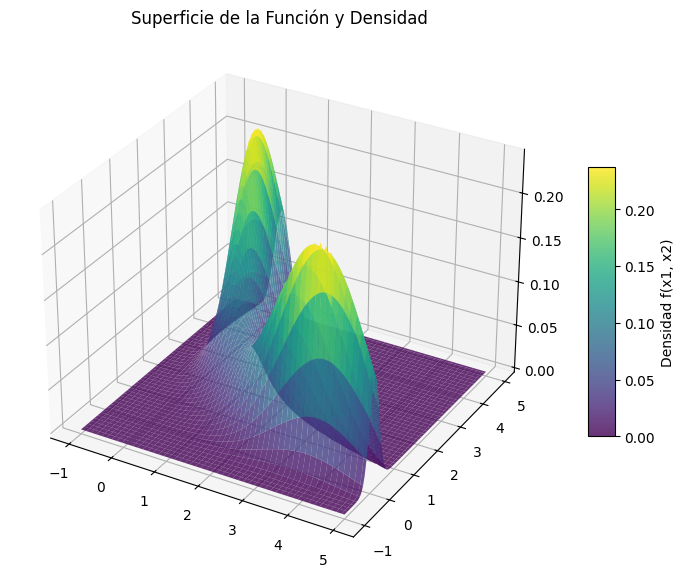

In [ ]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
x1_rango = np.linspace(-1, 5, 100)
x2_rango = np.linspace(-1, 5, 100)
X1, X2 = np.meshgrid(x1_rango, x2_rango)
Z_func = funcion(X1, X2)
superficie = ax.plot_surface(X1, X2, Z_func, cmap='viridis', alpha=0.8, edgecolor='none')
ax.set_title('Superficie de la Función y Densidad')
fig.colorbar(superficie, ax=ax, shrink=0.5, aspect=10, label='Densidad f(x1, x2)')

plt.show()